## 02-多路查询（Multi-Query）
- 要解决的问题：用户问题与知识库中的原始文档存在巨大的表达差异
- 基本思路：
    - 利用 LLM 生成 N 个与原始查询相关的问题
    - 将所有问题（加上原始查询）发送给检索系统
    - 通过这种方法，可以从向量库中检索到更多文档

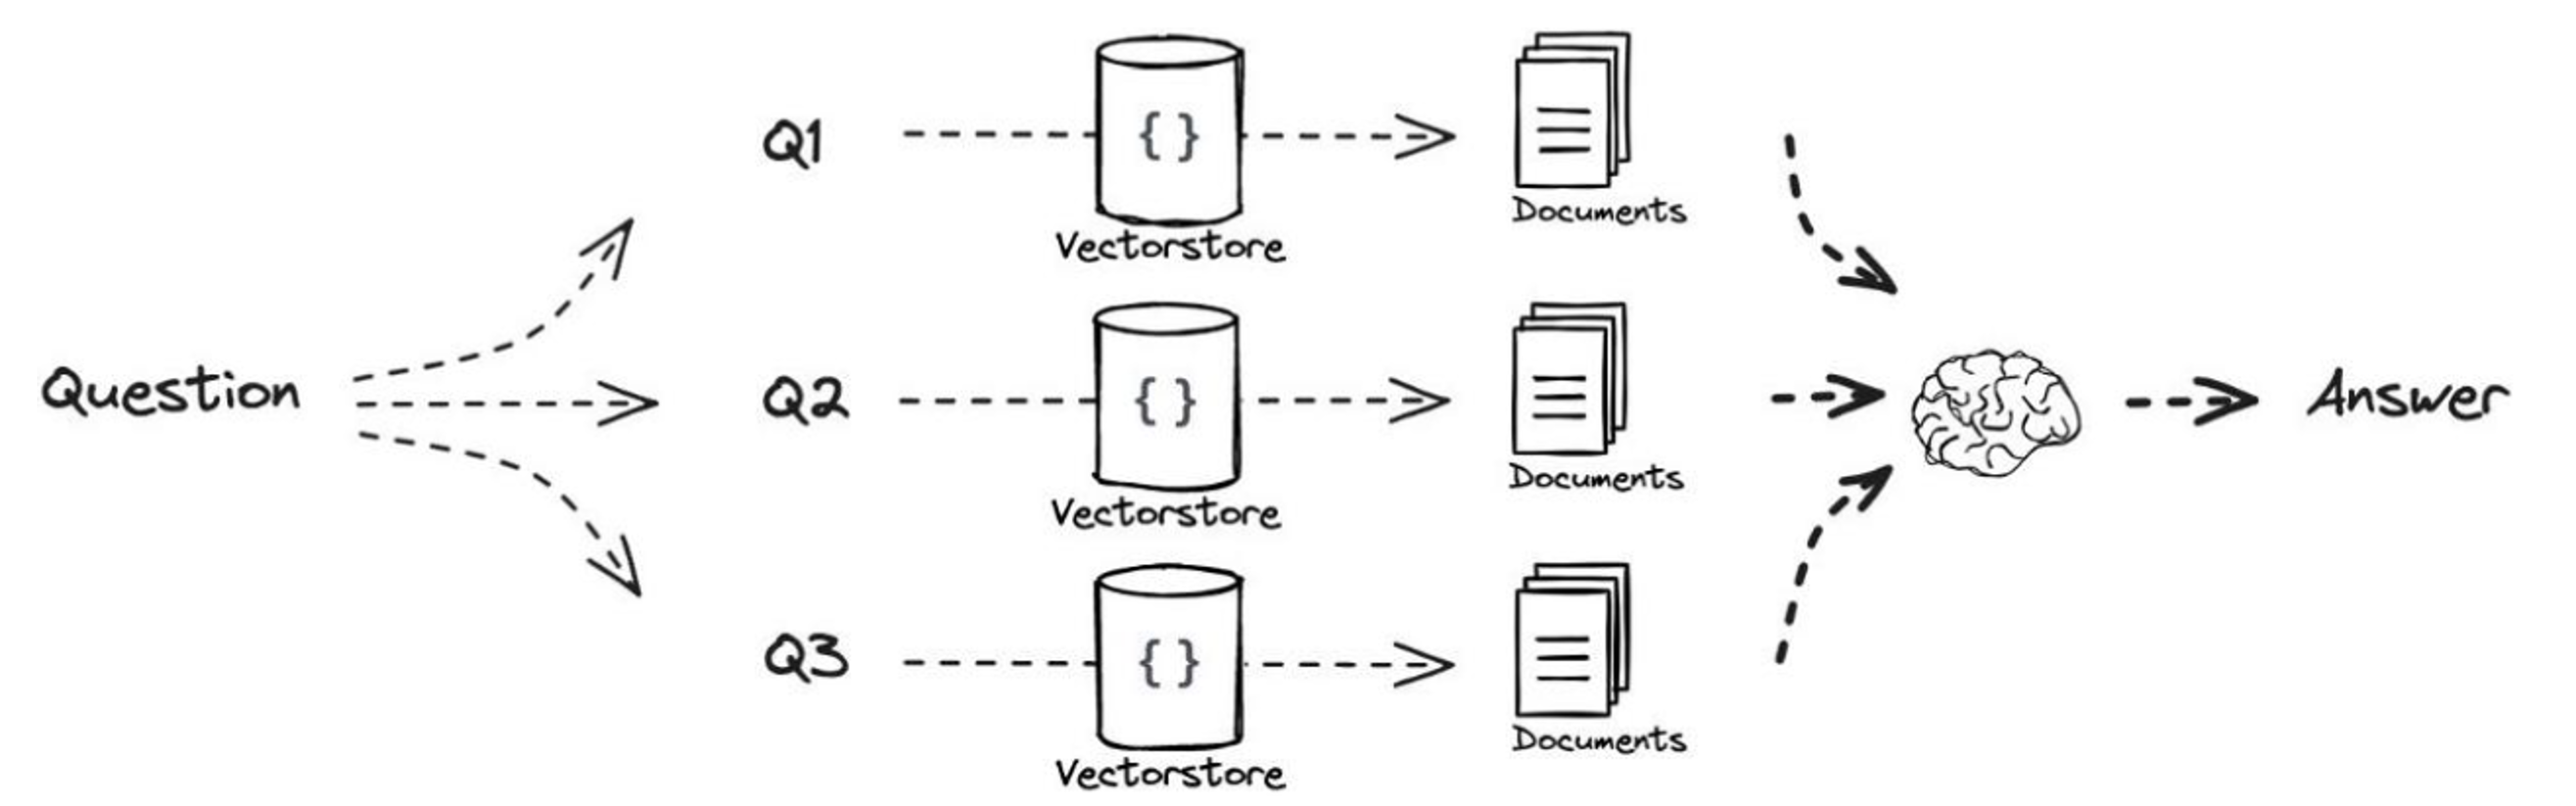

#### 对话模型

In [1]:
import os
from langchain_openai import ChatOpenAI
llm = ChatOpenAI(api_key=os.getenv("DASHSCOPE_API_KEY"), model="qwen3.7-max", base_url="https://ws-ots0tb33v08803wb.cn-beijing.maas.aliyuncs.com/compatible-mode/v1")

#### 嵌入模型

In [2]:
from langchain_community.embeddings import DashScopeEmbeddings
embeddings_model = DashScopeEmbeddings(model="text-embedding-v4", dashscope_api_key=os.getenv("DASHSCOPE_API_KEY"))

# 通过本地ollama上运行的bge-m3做向量化, 使用需要关闭 代理/VPN
from langchain_ollama import OllamaEmbeddings
embeddings_model = OllamaEmbeddings(model="bge-m3")

#### 文档加载

In [3]:
from langchain_community.document_loaders import TextLoader
# 加载数据
loader = TextLoader("../../../data/deepseek百度百科.txt", encoding="utf-8")
docs = loader.load()
print(f"文章的长度：{len(docs[0].page_content)}")

文章的长度：20899


#### 文档分块

In [4]:
from langchain_text_splitters import RecursiveCharacterTextSplitter
text_splitter = RecursiveCharacterTextSplitter(chunk_size=1024, chunk_overlap=100)
docs = text_splitter.split_documents(docs)
print(f"切分后的块数：{len(docs)} 个块")
for i, doc in enumerate(docs):
    print(f"--------Chunk {i+1} {len(doc.page_content)} 个字符---------")
    print(doc.metadata)
    print(doc.page_content)
    print()

切分后的块数：27 个块
--------Chunk 1 763 个字符---------
{'source': '../../../data/deepseek百度百科.txt'}
DeepSeek，全称杭州深度求索人工智能基础技术研究有限公司。DeepSeek是一家创新型科技公司，成立于2023年7月17日 ，使用数据蒸馏技术，得到更为精炼、有用的数据。由知名私募巨头幻方量化孕育而生，专注于开发先进的大语言模型（LLM）和相关技术。注册地址：浙江省杭州市拱墅区环城北路169号汇金国际大厦西1幢1201室。法定代表人为裴湉，经营范围包括技术服务、技术开发、软件开发等。
2024年1月5日至6月，相继发布DeepSeek LLM、DeepSeek-Coder、DeepSeekMath、DeepSeek-VL、DeepSeek-V2、DeepSeek-Coder-V2模型。 2024年9月5日，更新API支持文档，宣布合并DeepSeek Coder V2和DeepSeek V2 Chat，推出DeepSeek V2.5。12月13日，发布DeepSeek-VL2。12月26日，正式上线DeepSeek-V3首个版本并同步开源。2025年1月31日，英伟达宣布DeepSeek-R1模型登陆NVIDIANIM。同一时段内，亚马逊和微软也接入DeepSeek-R1模型。 2月5日，DeepSeek-R1、V3、Coder等系列模型，已陆续上线国家超算互联网平台。2月6日消息，澳大利亚政府以所谓“担心安全风险”为由，已禁止在所有政府设备中使用DeepSeek。2月8日，DeepSeek正式登陆苏州，并在苏州市公共算力服务平台上完成部署上线，为用户提供开箱即用的软硬件一体服务。 截至2月9日，DeepSeek App的累计下载量已超1.1亿次，周活跃用户规模最高近9700万。 2月20日消息，已有超200家企业宣布接入DeepSeek。 2月26日，DeepSeek宣布开源DeepGEMM。

--------Chunk 2 580 个字符---------
{'source': '../../../data/deepseek百度百科.txt'}
发展历程
早期发展
DeepSeek成立于2023年7月17日，由知名量化资管巨头幻方量化创立。DeepSeek是一家创新型科技公司

#### VectorStore

In [5]:
from langchain_community.vectorstores import Chroma
vectorstore = Chroma.from_documents(documents=docs, embedding=embeddings_model) # 创建向量数据库
retriever = vectorstore.as_retriever() # 创建检索器

# 检索测试
relevant_docs= retriever.invoke('deepseek的应用场景')
# 查看一下检索到的相关文档的数量：
print("-" * 60)
print("检索器检索的文档数量为：",len(relevant_docs))
print("-" * 60)
# print("检索器检索的文档为：", relevant_docs)
for i, doc in enumerate(relevant_docs):
    print(f"--------relevant_docs {i+1} {len(doc.page_content)} 个字符---------")
    print(doc.metadata)
    print(doc.page_content)
    print()
print("-" * 60)
# 检索测试-完成

------------------------------------------------------------
检索器检索的文档数量为： 4
------------------------------------------------------------
--------relevant_docs 1 763 个字符---------
{'source': '../../../data/deepseek百度百科.txt'}
DeepSeek，全称杭州深度求索人工智能基础技术研究有限公司。DeepSeek是一家创新型科技公司，成立于2023年7月17日 ，使用数据蒸馏技术，得到更为精炼、有用的数据。由知名私募巨头幻方量化孕育而生，专注于开发先进的大语言模型（LLM）和相关技术。注册地址：浙江省杭州市拱墅区环城北路169号汇金国际大厦西1幢1201室。法定代表人为裴湉，经营范围包括技术服务、技术开发、软件开发等。
2024年1月5日至6月，相继发布DeepSeek LLM、DeepSeek-Coder、DeepSeekMath、DeepSeek-VL、DeepSeek-V2、DeepSeek-Coder-V2模型。 2024年9月5日，更新API支持文档，宣布合并DeepSeek Coder V2和DeepSeek V2 Chat，推出DeepSeek V2.5。12月13日，发布DeepSeek-VL2。12月26日，正式上线DeepSeek-V3首个版本并同步开源。2025年1月31日，英伟达宣布DeepSeek-R1模型登陆NVIDIANIM。同一时段内，亚马逊和微软也接入DeepSeek-R1模型。 2月5日，DeepSeek-R1、V3、Coder等系列模型，已陆续上线国家超算互联网平台。2月6日消息，澳大利亚政府以所谓“担心安全风险”为由，已禁止在所有政府设备中使用DeepSeek。2月8日，DeepSeek正式登陆苏州，并在苏州市公共算力服务平台上完成部署上线，为用户提供开箱即用的软硬件一体服务。 截至2月9日，DeepSeek App的累计下载量已超1.1亿次，周活跃用户规模最高近9700万。 2月20日消息，已有超200家企业宣布接入DeepSeek。 2月26日，DeepSeek宣布开源DeepGEMM。

--------rele

#### 用 LLM 为用户问题生成多个相关问题 `MultiQueryRetriever`

In [6]:
# 引入日志组件查看llm在原查询的基础上生成的多个查询
import logging
logging.basicConfig()
# 设置获取日志的对象、日志级别
logging.getLogger("langchain_classic.retrievers.multi_query").setLevel(logging.INFO)

In [7]:
from langchain_classic.retrievers import MultiQueryRetriever
from langchain_core.prompts import ChatPromptTemplate

# 自定义提示词、用来实现多路查询,生成分解的逻辑，需要结合领域特性来制定。
multi_query_prompt = ChatPromptTemplate.from_template(
    '''你是一个AI语言模型助手。你的任务是生成5个给定用户问题的不同版本，以从向量中检索相关文档
数据库。通过对用户问题产生多种观点，你的目标是提供帮助用户克服了基于距离的相似性搜索的一些限制。
提供了这些用换行符隔开的可选问题。原始问题: {question}
''')

# MultiQueryRetriever是对查询的优化
retrieval_from_llm = MultiQueryRetriever.from_llm(
    prompt=multi_query_prompt,  # 使用自定义提示词，不给就会使用默认的提示词
    retriever=retriever,  # 使用的检索器
    llm=llm,  # 使用的大模型
)

In [8]:
# 多路检索测试
relevant_docs= retrieval_from_llm.invoke('deepseek的应用场景')
# 查看一下检索到的相关文档的数量：
print("-" * 60)
print("检索器检索的文档数量为：",len(relevant_docs))
print("-" * 60)
# print("检索器检索的文档为：", relevant_docs)
for i, doc in enumerate(relevant_docs):
    print(f"--------relevant_docs {i+1} {len(doc.page_content)} 个字符---------")
    print(doc.metadata)
    print(doc.page_content)
    print()
print("-" * 60)
# 多路检索测试-完成

INFO:langchain_classic.retrievers.multi_query:Generated queries: ['DeepSeek大模型具体能用来做什么？有哪些常见的实际用途？', 'DeepSeek在哪些行业或业务领域有成熟的落地应用和解决方案？', '基于DeepSeek的技术能力，它适合处理哪些具体的下游任务和开发场景？', '企业如何接入并利用DeepSeek模型来赋能自身的实际业务？', '目前有哪些DeepSeek在真实环境中的典型应用案例和实践示范？']


------------------------------------------------------------
检索器检索的文档数量为： 9
------------------------------------------------------------
--------relevant_docs 1 825 个字符---------
{'source': '../../../data/deepseek百度百科.txt'}
相关评价
“DeepSeek新一代模型的发布意味着AI大模型的应用将逐步走向普惠，助力AI应用广泛落地；同时训练效率大幅提升，亦将助力推理算力需求高增。我们持续看好AI产业链的加速落地机遇，建议重点关注AI应用、AI Infra、AI算力三大主线。”（中信证券研报 评）
DeepSeek-V3是中国科技界带给美国的苦涩教训。“当美国休息时，中国（科技界）在工作，以更低的成本、更快的速度和更强的实力赶上。”（Alexander Wang 评）
DeepSeek可能是个国运级别的科技成果。（游戏科学创始人、CEO，《黑神话：悟空》制作人冯骥 2025年1月26日评）
DeepSeek-R1是一款令人印象深刻的模型，尤其是考虑到它能够以这个价格提供（这样的产品）。（美国开放人工智能研究中心（OpenAI）首席执行官萨姆·奥尔特曼 评）
DeepSeek引发全球轰动和一些人的焦虑恐慌，说明技术遏制和技术限制无法奏效，这是全世界、特别是美国需要学习的一课。（中国常驻联合国代表傅聪评）
DeepSeek在电池知识问答和电池文本挖掘任务上均表现优异，在电池设计任务上具备初步的总结能力，但尚欠缺科学分析能力，仍需要垂直领域大模型解决。（中国科学院院士、平台理事长欧阳明高 评）
DeepSeek公司取得的重大进展，代表着一批中国公司在人工智能领域的崛起。DeepSeek公司坚持开放开源的技术路线，开源共享推动了人工智能技术在全球的普遍应用，为世界贡献了“中国智慧”。通过DeepSeek这类公司的兴起，我们可以看到中国在科技发展上的创新性和包容性。（十四届全国人大三次会议大会发言人娄勤俭 评）
2025年3月7日，全球著名投资基金、咨询公司Andreessen Horowitz（简称a16z）发布2025年全球100生成式AI应用排行榜。本次榜单一

### 用户查询

In [12]:
from langchain_core.output_parsers import StrOutputParser   # 字符串输出解析器
from langchain_core.prompts import ChatPromptTemplate  # 聊天提示模板
from operator import itemgetter

template = """请根据下面给出的上下文来回答问题:
{context}
问题: {question}
"""

prompt = ChatPromptTemplate.from_template(template)

# 多路查询
final_rag_chain = (
        {
            "context": lambda x: retrieval_from_llm.invoke(x["question"]),
            "question": itemgetter("question")
        }
        | prompt | llm | StrOutputParser()
)

question = "deepseek的应用场景"
response = final_rag_chain.invoke({"question": question})
print("=====使用多路查询后，大模型生成的回答：=====\n", response)

INFO:langchain_classic.retrievers.multi_query:Generated queries: ['DeepSeek大模型在实际工作和日常生活中有哪些具体的用途与落地案例？', '结合DeepSeek在代码生成和复杂逻辑推理方面的技术优势，它最适合解决哪些特定领域的业务问题？', '企业开发者如何利用DeepSeek开源模型进行私有化部署并构建定制化的行业AI应用？', 'DeepSeek在软件开发、金融分析、教育培训等垂直行业中，有哪些典型的AI赋能场景？', '凭借高性价比和强大的长文本处理能力，DeepSeek在哪些需要处理海量数据或高并发请求的商业场景中更具优势？']


=====使用多路查询后，大模型生成的回答：=====
 根据提供的上下文，DeepSeek的应用场景非常广泛，已深入多个行业和领域。具体应用场景可归纳为以下几类：

**1. 政务服务与城市治理**
* **政务系统与外网部署**：在广州、珠海、江苏多地、湖南桑植县（推出政务助手“桑智”）等地的政务外网和政务系统中进行本地化部署。
* **政务智能客服**：应用于西安浐灞国际港政务服务智能客服“D小港”等，提供高效精准的智慧化服务。
* **民生热线**：接入辽宁12345热线平台，形成智能交互、治理与分析的闭环管理体系。
* **乡村治理**：接入佛山“江义村智慧乡村平台”，助力乡村治理。
* **智慧城市**：与呼和浩特市“城市大脑”进行初步集成。

**2. 交通与汽车制造**
* **智能座舱**：上汽大众的智能座舱已完成搭载DeepSeek大模型。
* **工业质检**：理想汽车在工厂质检环节搭载DeepSeek-VL视觉大模型，作为“硅基质检员”上岗。

**3. 医疗与公共卫生**
* **心理健康诊疗**：成都市第四人民医院利用其结合“生物情绪心智三元模型整合治疗”，提高心理健康诊疗个性化的精准度。
* **疾病预防控制**：安徽省疾控中心完成“讯飞星火医疗大模型+DeepSeek”的本地化部署，赋能疾病防控。

**4. 互联网与日常应用**
* **AI搜索**：微信“搜一搜”灰度测试接入DeepSeek-R1，为用户提供“深度思考”选项。
* **AI助手/聊天机器人**：作为AI应用在全球多国App Store和Play Store登顶，供大众日常使用。
* **游戏互动**：腾讯旗下手游《和平精英》正式接入，成为首款接入该模型的游戏。

**5. 教育与科研选拔**
* **高校部署**：武汉大学信息中心完成全系大模型部署调试，满血版上线武大。
* **老年教育**：广州老年大学开设全国首个DeepSeek班，教授《DeepSeek+AI作图》课程。
* **招飞选拔**：参与2025年度空军招飞定选的面试工作。
* **科研与垂直领域**：在电池知识问答、电池文本挖掘及电池设计任务中展现能力；第一财经技术中心将其作为基座模型研发财经垂类大模型。

**6. 文旅与酒店服务**
* **智慧文旅**：中国电信重庆公司联合多方打造合川钓鱼城

In [ ]:
# 原始查询
chain = (
        {
            "context": lambda x: retriever.invoke(x["question"]),
            "question": itemgetter("question")
        }
        | prompt | llm | StrOutputParser()
)
response = chain.invoke({"question": question})
print("=====没有多路查询前，大模型生成的回答：=====\n", response)